# jaxsedfit: fit one SED

This notebook fits the broadband SED of one *Chimera*: a real COSMOS galaxy with a scaled SDSS quasar spectrum added, so the true stellar mass is known. It covers

1. loading photometry and building a `FitConfig`;
2. running the fit;
3. comparing the recovered stellar mass to the truth;
4. plotting the SED, its components, and the posterior.

You need the DSPS SSP template file `tempdata.h5` in the repository root (see the installation instructions).

In [1]:
import numpy as np
import numpyro.distributions as dist
from astropy.table import Table

from jaxsedfit import (
    AGNConfig,
    FilterSet,
    FitConfig,
    GalaxyConfig,
    InferenceConfig,
    JAXSEDFit,
    LikelihoodConfig,
    Observation,
    PhotometryData,
    PriorConfig,
    load_filter_curves,
)

## 1. Photometry

Fluxes and errors are in mJy. The table metadata hold the redshift and the true stellar mass of the Chimera.

In [2]:
phot = Table.read("data/chimera_cosmos_922124.ecsv")
z = phot.meta["redshift"]
truth_log_mass = phot.meta["log_stellar_mass_truth"]
print(f"{phot.meta['object_id']}: z = {z:.3f}, true log M* = {truth_log_mass:.2f}")
phot

030021.40-071458.9_922124_0.0003: z = 0.398, true log M* = 10.12


filter_name,flux_mjy,flux_err_mjy
str15,float64,float64
u_sdss,0.00025331657955940254,3.123508830083581e-05
r_sdss,0.0003038510721782023,3.8312674629606975e-05
i_sdss,0.0003715890196243841,4.856620356856323e-05
z_sdss,0.0005711494637471579,7.589343455725554e-05
J_2mass,0.0010122502781788692,0.00012662330060106536
H_2mass,0.0017562040839901442,0.0008353384510674151
Ks_2mass,0.0020115865404269524,0.0010281453452213114
spitzer.irac.I1,0.004865438974827159,4.015222831958586e-05
spitzer.irac.I2,0.006654959433576658,7.821918976679058e-05


## 2. Configure the fit

`FitConfig` groups the settings by section:

- `observation`: redshift (fixed here; `redshift_mode="fit"` with a `RedshiftPriorConfig` fits it as a photo-z, see the Fairall 9 photo-z tutorial);
- `photometry` and `filters`: the data and the filter transmission curves;
- `galaxy`: the stellar population, dust and SFH settings, including the DSPS SSP file;
- `agn`: the AGN model; `agn_type=1` is a type-1 quasar, `2` a Seyfert 2 and `3` a LINER;
- `likelihood`: error model options; `use_local_line_photometry` integrates emission lines through each filter exactly;
- `inference`: `method="optax+nuts"` (MAP warm start, then NUTS), `"optax"` (MAP only), or `"ns"` (nested sampling, with `ns_num_live_points`, `ns_max_samples`, `ns_dlogz`);
- `prior_config`: priors; here a broad Student-t prior on log stellar mass.

In [3]:
config = FitConfig(
    observation=Observation(object_id=phot.meta["object_id"], redshift=z, redshift_mode="fixed"),
    photometry=PhotometryData(
        filter_names=list(phot["filter_name"]),
        fluxes=list(phot["flux_mjy"]),
        errors=list(phot["flux_err_mjy"]),
    ),
    filters=FilterSet(curves=load_filter_curves(list(phot["filter_name"]))),
    galaxy=GalaxyConfig(dsps_ssp_fn="../tempdata.h5"),
    agn=AGNConfig(agn_type=1),
    likelihood=LikelihoodConfig(use_local_line_photometry=True),
    inference=InferenceConfig(
        method="optax+nuts",
        map_steps=400,
        learning_rate=5e-3,
        num_warmup=400,
        num_samples=200,
        max_tree_depth=8,
        target_accept_prob=0.8,
    ),
    prior_config=PriorConfig(stellar_mass=dist.StudentT(df=5.0, loc=10.0, scale=2.0)),
)

## 3. Fit and compare to the truth

In [4]:
fitter = JAXSEDFit(config)
result = fitter.fit(progress_bar=False)

lo, mid, hi = np.percentile(result.samples["log_stellar_mass"], [16, 50, 84])
print(f"log M*: {mid:.2f} (+{hi - mid:.2f}/-{mid - lo:.2f}), truth {truth_log_mass:.2f}, residual {mid - truth_log_mass:+.2f} dex")


                                 mean       std    median      5.0%     95.0%     n_eff     r_hat
       broad_lines_strength      3.47      4.32      1.60      0.30      8.57    169.16      1.00
                   cool_lam     21.21      5.87     21.94     12.82     29.97    191.15      1.01
                 cool_width      0.41      0.14      0.40      0.21      0.61    258.31      1.00
                 dust_alpha      1.76      0.55      1.74      0.80      2.50    256.16      1.00
                       fcov      0.60      0.26      0.64      0.19      0.95    128.18      1.00
                  feii_norm      9.82      9.08      6.21      0.65     24.76    205.75      1.03
                    hot_lam      2.72      1.34      2.24      1.01      4.97     44.95      1.00
                  hot_width      0.45      0.12      0.47      0.28      0.65     98.59      1.00
                log_agn_amp     80.52      1.10     80.59     78.90     82.35     48.76      1.01
  log_agn_systemati

log M*: 7.34 (+0.78/-0.36), truth 10.12, residual -2.78 dex


/Users/colinburke/research/jaxsedfit-tutorials/src/jaxsedfit/results.py:30: RuntimeWarning: All-NaN slice encountered
  out[key] = np.nanmedian(arr, axis=0)


## 4. SED and components

`plot_sed` draws the total model, the stellar host, the dust re-emission and the AGN components with the observed photometry. `predict()` returns the same model evaluated in each band; the first element of each array is the posterior median.

/Users/colinburke/research/jaxsedfit-tutorials/src/jaxsedfit/plotting.py:1044: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


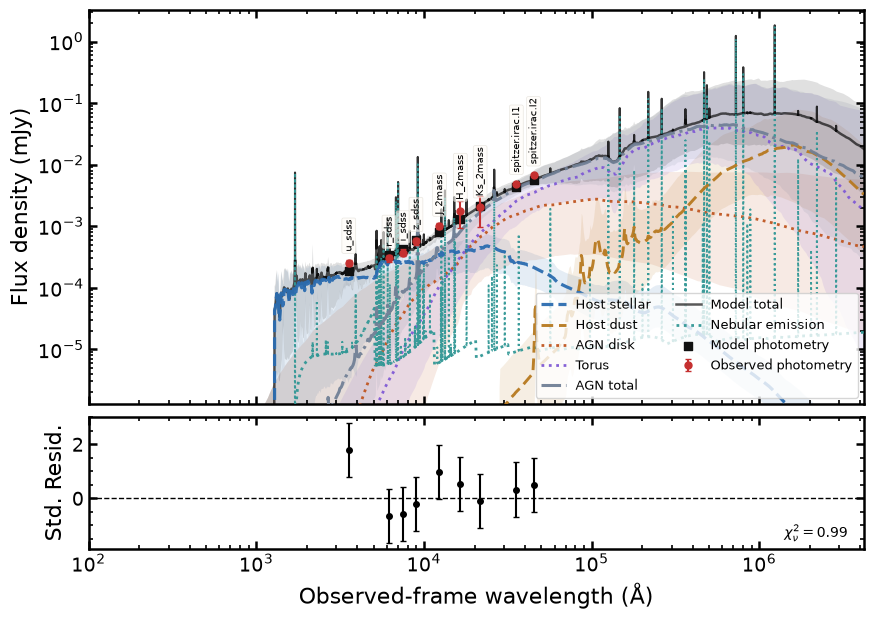

In [5]:
fitter.plot_sed(show=True);

In [6]:
pred = fitter.predict()
Table(
    {
        "filter": phot["filter_name"],
        "observed": phot["flux_mjy"],
        "model": pred["pred_fluxes"][0],
        "host": pred["host_fluxes"][0],
        "dust": pred["dust_fluxes"][0],
        "agn": pred["agn_fluxes"][0],
    }
)

filter,observed,model,host,dust,agn
str15,float64,float64,float64,float64,float64
u_sdss,0.00025331657955940254,0.00012204787458596404,0.00012196379727259577,0.0,8.407731336824373e-08
r_sdss,0.0003038510721782023,0.0003375877749551176,0.00033095518644970563,0.0,6.6325885054118934e-06
i_sdss,0.0003715890196243841,0.0004197102197897158,0.0004004049753535289,0.0,1.9305244436186934e-05
z_sdss,0.0005711494637471579,0.0005831252931926087,0.0004581806643675404,0.0,0.0001249446288250684
J_2mass,0.0010122502781788692,0.0007800880550675255,0.0005930134764594942,0.0,0.0001870745786080313
H_2mass,0.0017562040839901442,0.0012445568642470621,0.0007050211946330576,0.0,0.0005395356696140044
Ks_2mass,0.0020115865404269524,0.002161364093711326,0.0007825003025350583,0.0,0.0013788637911762674
spitzer.irac.I1,0.004865438974827159,0.004070159493162704,0.0004814779750685597,6.096063717276491e-06,0.003582585454376867
spitzer.irac.I2,0.006654959433576658,0.005445477375259073,0.00040204362303876293,2.96420122834208e-05,0.005013791739936888


## 5. Posterior

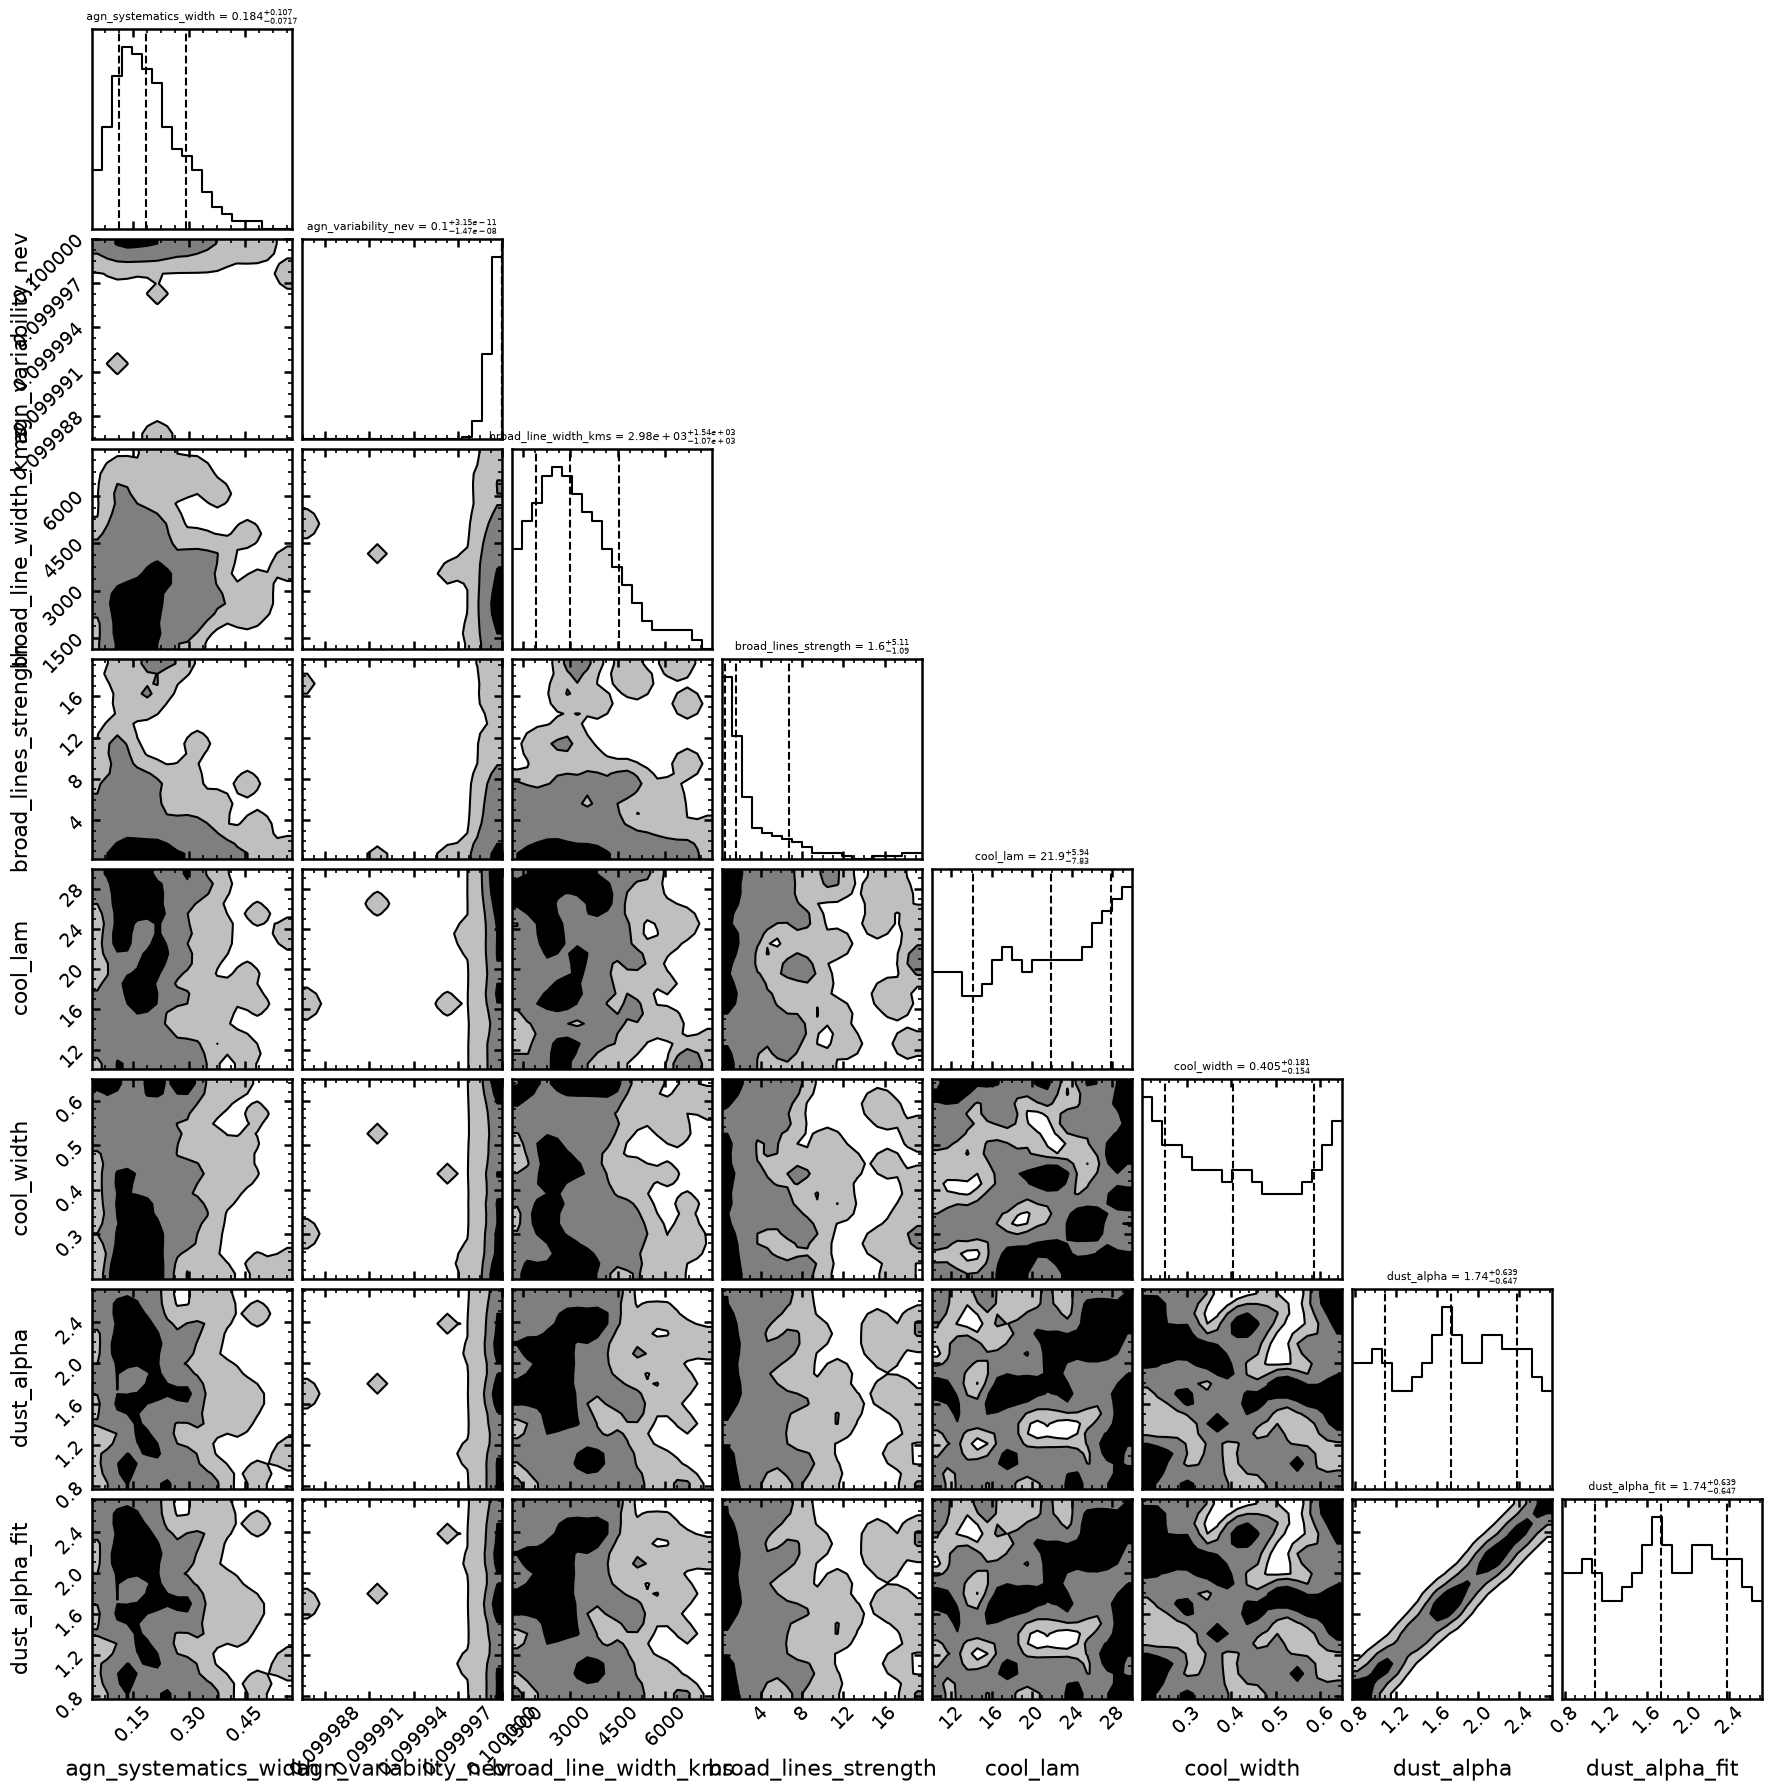

In [7]:
fitter.plot_corner(max_params=8, show=True);

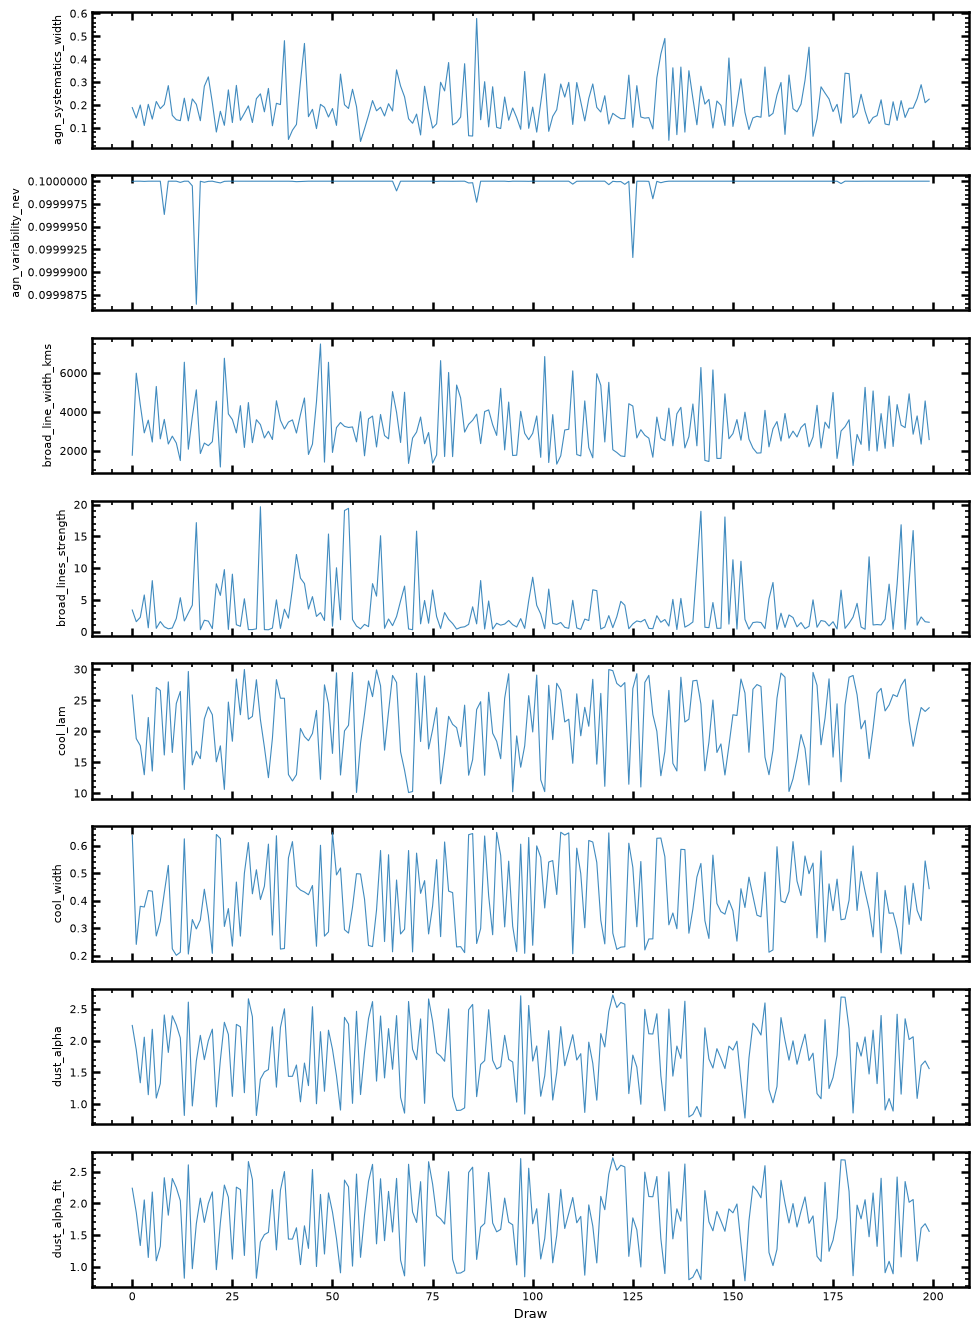

In [8]:
fitter.plot_trace(max_params=8, show=True);

## Next steps

- Increase `map_steps`, `num_warmup` and `num_samples` for science fits.
- Try `method="ns"` to compare with nested sampling.
- Save the posterior with `result.save(...)` and reload it with `jaxsedfit.load(...)`.